# PNEUMYST AI · Training

TB model first (TBX11K), NIH model 
later. Checkpoints go to `ml/checkpoints/<run_name>/` (git-ignored); rerunning a training cell resumes from `last.pt`.

In [1]:
import json, shutil, sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

from dotenv import load_dotenv
load_dotenv(REPO / ".env")

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image

from ml.config import data_root
from ml.training import train as tr
from ml.training.augment import AugConfig, augment
from ml.training.data import load_processed
from ml.training.metrics import banded_auroc, binary_report, bootstrap_auroc, threshold_for_sensitivity

ROOT = data_root()
FIG = REPO / "docs" / "figures" / "training"
FIG.mkdir(parents=True, exist_ok=True)
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

torch 2.11.0+cu128 | CUDA: True | NVIDIA GeForce RTX 3050 Laptop GPU


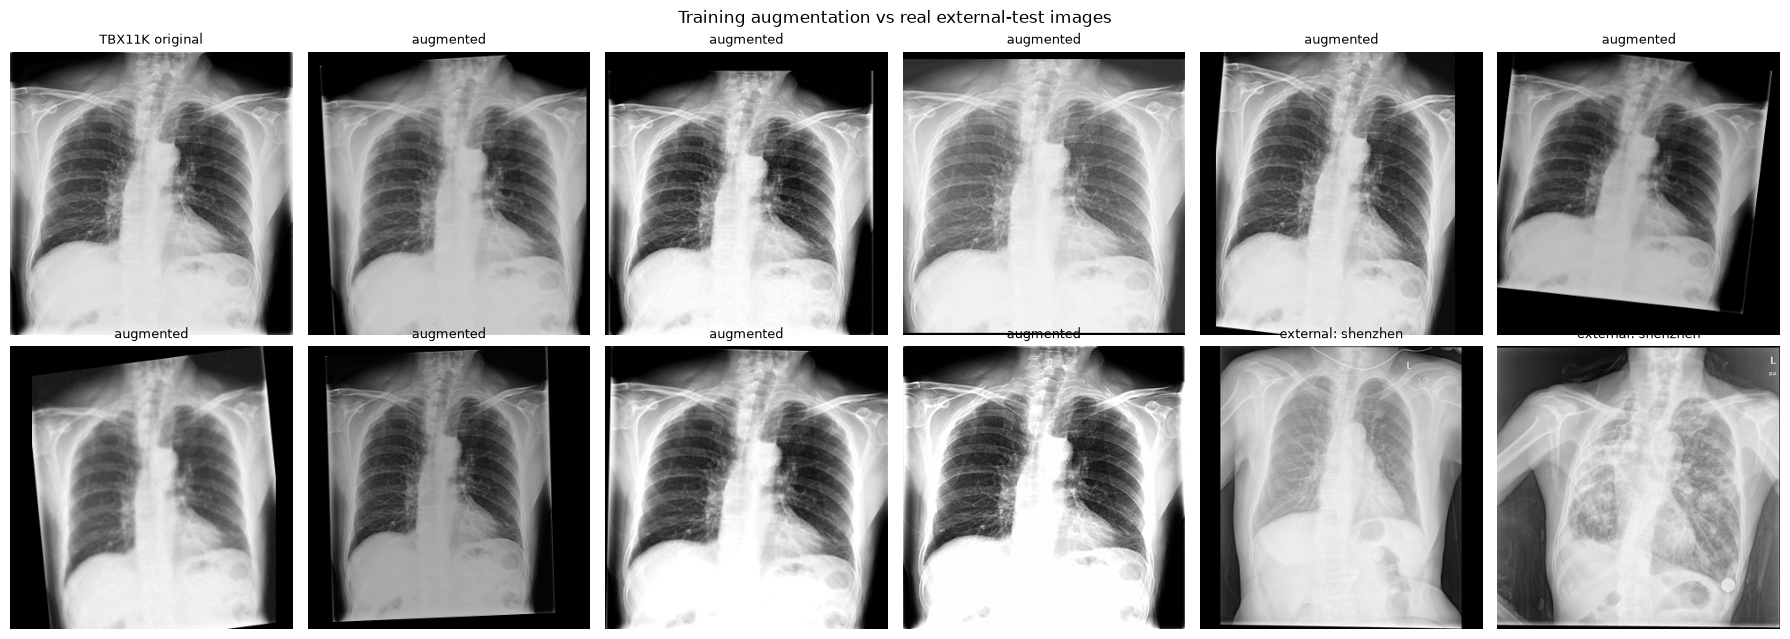

In [2]:
tbx = load_processed(ROOT, "tbx11k")
ext = pd.concat([load_processed(ROOT, s) for s in ("shenzhen", "montgomery")])
img = np.asarray(Image.open(ROOT / tbx[tbx["split"] == "train"].iloc[0]["processed_path"]))
rng = np.random.default_rng(0)
aug_cfg = AugConfig(pad_p=0.5)

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255); axes[0, 0].set_title("TBX11K original", fontsize=9)
for ax in list(axes.ravel()[1:10]):
    ax.imshow(augment(img, rng, aug_cfg), cmap="gray", vmin=0, vmax=255); ax.set_title("augmented", fontsize=9)
for ax, (_, r) in zip(axes.ravel()[10:], ext.sample(2, random_state=1).iterrows()):
    ax.imshow(np.asarray(Image.open(ROOT / r["processed_path"])), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"external: {r['source']}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Training augmentation vs real external-test images")
plt.tight_layout(); plt.show()

In [3]:
BATCH = tr.find_batch_size(tr.TrainConfig(task="tb")) or 8
ACCUM = max(1, 32 // BATCH)   # effective batch ≈ 32
print(f"batch {BATCH} x accum {ACCUM} = effective {BATCH * ACCUM}")

batch 32: ok, peak 2.23 GB
batch 32 x accum 1 = effective 32


In [4]:
smoke_dir = REPO / "ml" / "checkpoints" / "smoke_tb"
shutil.rmtree(smoke_dir, ignore_errors=True)
smoke = tr.fit(tr.TrainConfig(task="tb", run_name="smoke_tb", epochs=2, frozen_epochs=1, batch_size=BATCH,
                              accum_steps=ACCUM, limit=256, workers=0), ROOT, run_dir=smoke_dir)
display(smoke["history"])
shutil.rmtree(smoke_dir, ignore_errors=True)

tb: train 256 | val 256 | device cuda | pos_weight [7.5]
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to C:\Users\krish.LAPTOP-3EPNQNP7/.cache\torch\hub\checkpoints\densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:17<00:00, 1.85MB/s]
c:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-ai\ml\training\train.py:116: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


epoch 1/2 (frozen) | train 1.3357 | val 1.2309 | metric 0.4629 | 0.13 min *best*
epoch 2/2 | train 1.2820 | val 1.0942 | metric 0.8169 | 0.8 min *best*


,epoch,frozen,train_loss,val_loss,lr_backbone,minutes,metric,auroc,auprc,auroc_sick_vs_tb
0,1,True,1.3357,1.2309,0.000100,0.13,0.462859,0.462859,0.101338,0.388465
1,2,False,1.2820,1.0942,0.000001,0.80,0.816877,0.816877,0.528584,0.719866


In [5]:
cfg = tr.TrainConfig(task="tb", run_name="tb_densenet121_v1", epochs=20, frozen_epochs=2,
                     batch_size=BATCH, accum_steps=ACCUM, workers=4)
result = tr.fit(cfg, ROOT)   # if it stops, just rerun this cell: it resumes from last.pt
RUN = result["run_dir"]
hist = pd.read_json(RUN / "history.json")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hist.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", ax=axes[0], title="Loss")
hist.plot(x="epoch", y=["auroc", "auroc_sick_vs_tb", "auprc"], marker="o", ax=axes[1], title="Validation")
plt.tight_layout(); fig.savefig(FIG / "tb_v1_curves.png", dpi=150); plt.show()
hist

tb: train 5,479 | val 977 | device cuda | pos_weight [9.699999809265137]
epoch 1/20 (frozen) | train 1.2230 | val 1.0026 | metric 0.9171 | 1.09 min *best*
epoch 2/20 (frozen) | train 0.9604 | val 0.7731 | metric 0.9356 | 0.48 min *best*
epoch 3/20 | train 0.5545 | val 0.1353 | metric 0.9977 | 17.08 min *best*
epoch 4/20 | train 0.3410 | val 0.1820 | metric 0.9942 | 17.44 min
epoch 5/20 | train 0.2534 | val 0.0995 | metric 0.9986 | 16.85 min *best*
epoch 6/20 | train 0.1482 | val 0.1445 | metric 0.9993 | 17.01 min *best*
epoch 7/20 | train 0.0854 | val 0.0745 | metric 0.9993 | 17.13 min *best*
epoch 8/20 | train 0.0457 | val 0.2029 | metric 0.9989 | 16.58 min
epoch 9/20 | train 0.0492 | val 0.3327 | metric 0.9995 | 16.56 min *best*
epoch 10/20 | train 0.0341 | val 0.0906 | metric 0.9993 | 16.53 min
epoch 11/20 | train 0.0183 | val 0.1081 | metric 0.9999 | 16.54 min *best*
epoch 12/20 | train 0.0214 | val 0.0779 | metric 0.9996 | 16.53 min
epoch 13/20 | train 0.0193 | val 0.0795 | metric

KeyboardInterrupt: 

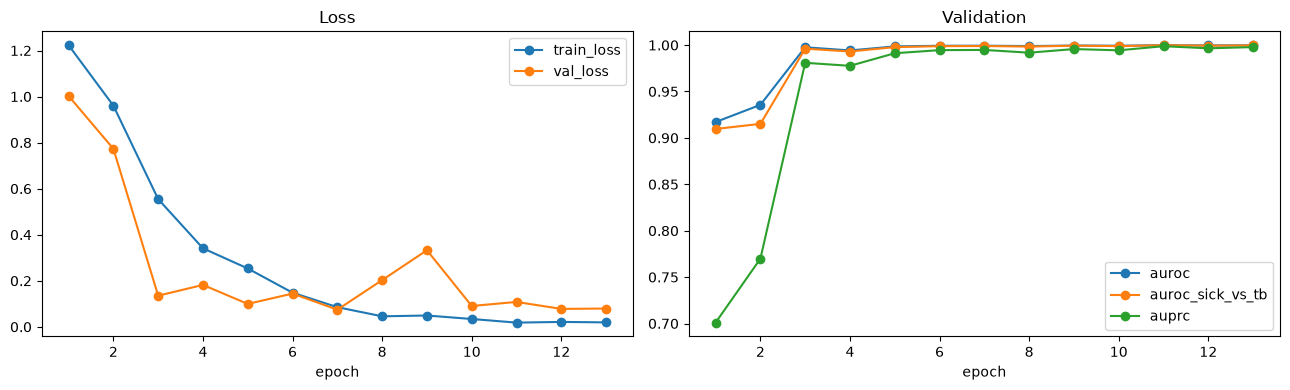

,epoch,frozen,train_loss,val_loss,lr_backbone,minutes,metric,auroc,auprc,auroc_sick_vs_tb
0,1,True,1.2230,1.0026,0.000100,1.09,0.917074,0.917074,0.700953,0.909624
1,2,True,0.9604,0.7731,0.000099,0.48,0.935613,0.935613,0.769814,0.915116
2,3,False,0.5545,0.1353,0.000097,17.08,0.997658,0.997658,0.980912,0.996135
3,4,False,0.3410,0.1820,0.000094,17.44,0.994225,0.994225,0.977666,0.993084
4,5,False,0.2534,0.0995,0.000090,16.85,0.998572,0.998572,0.991220,0.997788
5,6,False,0.1482,0.1445,0.000084,17.01,0.999286,0.999286,0.994563,0.998856
6,7,False,0.0854,0.0745,0.000078,17.13,0.999349,0.999349,0.994780,0.998983
7,8,False,0.0457,0.2029,0.000070,16.58,0.998948,0.998948,0.991811,0.998398
8,9,False,0.0492,0.3327,0.000063,16.56,0.999524,0.999524,0.995711,0.999364
9,10,False,0.0341,0.0906,0.000055,16.53,0.999324,0.999324,0.994361,0.998907


In [6]:
cfg = tr.TrainConfig(task="tb", run_name="tb_densenet121_v1")
RUN = REPO / "ml" / "checkpoints" / cfg.run_name
hist = pd.read_json(RUN / "history.json")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hist.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", ax=axes[0], title="Loss")
hist.plot(x="epoch", y=["auroc", "auroc_sick_vs_tb", "auprc"], marker="o", ax=axes[1], title="Validation")
plt.tight_layout(); fig.savefig(FIG / "tb_v1_curves.png", dpi=150); plt.show()
hist

In [7]:
val = pd.read_csv(RUN / "val_predictions.csv").merge(
    tbx[["image_id", "original_label", "px_sharpness", "px_mean"]], on="image_id")
y, p = val["label_tuberculosis"].to_numpy(), val["prob_tuberculosis"].to_numpy()
hard = val["original_label"].isin(["sick", "tb"]).to_numpy()

auc, lo, hi = bootstrap_auroc(y, p)
thr = threshold_for_sensitivity(y, p, 0.90)
report = binary_report(y, p, thr)
sick_vs_tb = binary_report(y[hard], p[hard], thr)["auroc"]
print(f"AUROC {auc:.3f} (95% CI {lo:.3f}-{hi:.3f}) | sick vs TB AUROC {sick_vs_tb:.3f} | threshold @90% sens {thr:.3f}")
display(pd.Series(report).to_frame("at threshold").T.round(3))

print("Score by original class:")
display(val.groupby("original_label")["prob_tuberculosis"].describe().round(3))

print("Shortcut check: AUROC inside sharpness / brightness bands (should stay close to overall):")
bands = pd.concat({"sharpness": banded_auroc(y, p, val["px_sharpness"]), "brightness": banded_auroc(y, p, val["px_mean"])})
display(bands.round(3))

summary = {"run": cfg.run_name, "best_epoch": int(hist.loc[hist["auroc"].idxmax(), "epoch"]),
           "auroc": auc, "auroc_ci": [lo, hi], "auroc_sick_vs_tb": sick_vs_tb, "threshold_90_sens": thr,
           "at_threshold": report, "bands": bands.reset_index(level=0).rename(columns={"level_0": "stat"}).to_dict("records")}
(FIG / "tb_v1_val_summary.json").write_text(json.dumps(summary, indent=2, default=str))

AUROC 1.000 (95% CI 1.000-1.000) | sick vs TB AUROC 1.000 | threshold @90% sens 0.987


,n,positives,threshold,auroc,auprc,sensitivity,specificity,ppv,npv,f1,tp,fp,tn,fn
at threshold,977.0,90.0,0.987,1.0,0.999,0.911,1.0,1.0,0.991,0.953,82.0,0.0,887.0,8.0


Score by original class:


,count,mean,std,min,25%,50%,75%,max
original_label,,,,,,,,
health,450.0,0.002,0.036,0.000,0.0,0.0,0.0,0.758
sick,437.0,0.001,0.006,0.000,0.0,0.0,0.0,0.112
tb,90.0,0.958,0.178,0.008,1.0,1.0,1.0,1.000


Shortcut check: AUROC inside sharpness / brightness bands (should stay close to overall):


band    n  positives  auroc
sharpness  0  (34.833000000000006, 86.701]  326          4  1.000
           1             (86.701, 122.758]  325         12  1.000
           2            (122.758, 542.221]  326         74  1.000
brightness 0  (66.54899999999999, 125.784]  326         22  0.999
           1            (125.784, 145.198]  325         50  1.000
           2            (145.198, 198.898]  326         18  1.000

1441